<a href="https://colab.research.google.com/github/scardenol/Numerical_Analysis_2026/blob/main/Taller%203/1_cristo_redentor_laplace.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller 3 — Punto 1: ¿Dónde le caen los rayos al Cristo Redentor?

Enunciado oficial

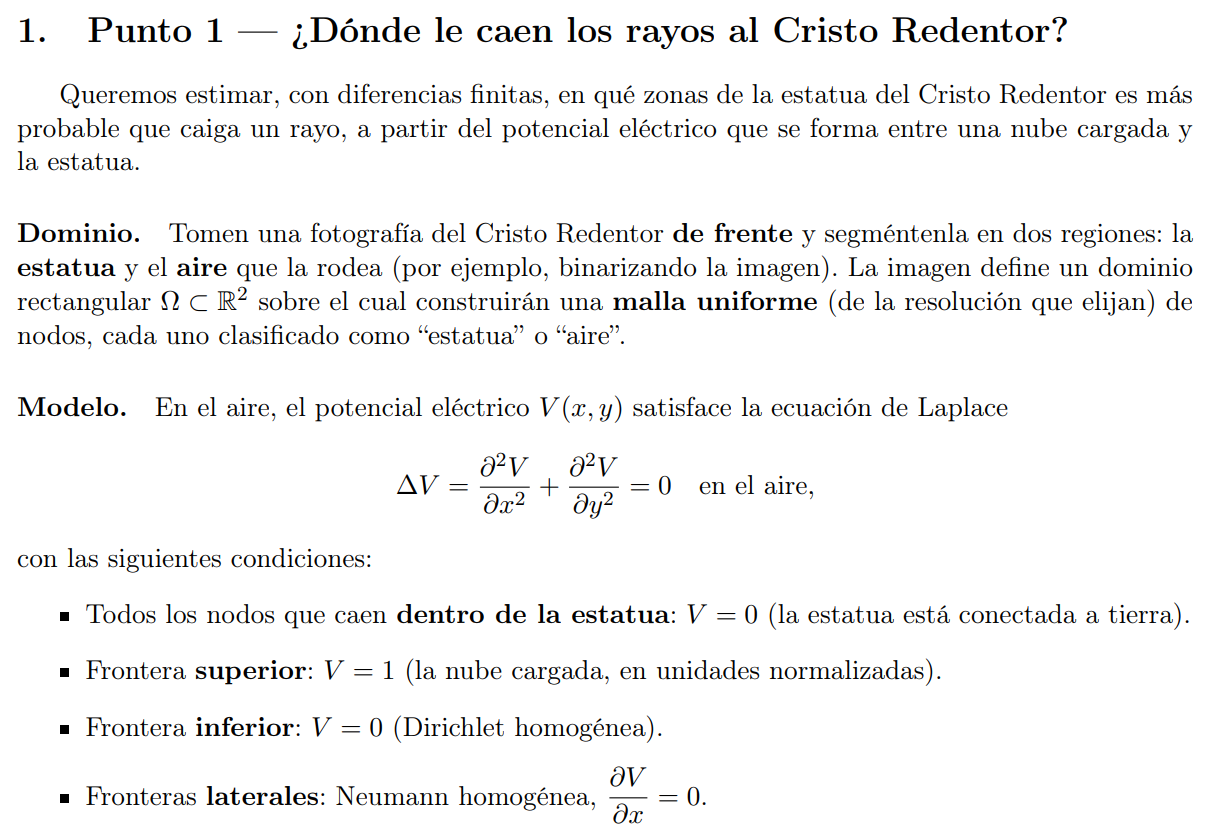

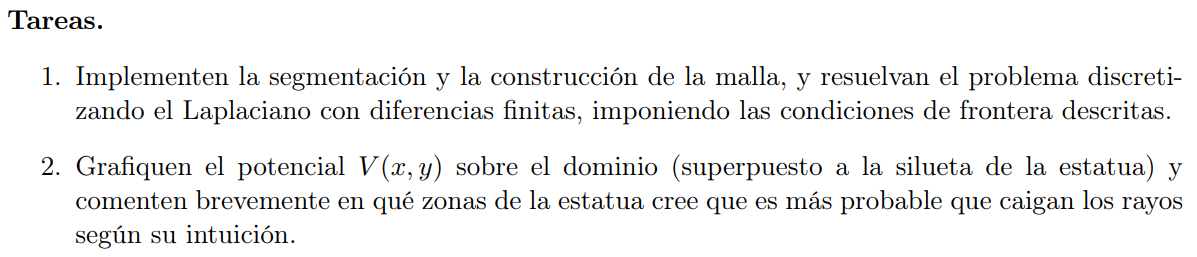

**Idea.** Entre una nube cargada (arriba) y la estatua conectada a la tierra se forma un potencial eléctrico o voltaje $V(x,y)$ que, en el aire, cumple la ecuación de Laplace. La idea es resolverla con diferencias finitas sobre una malla uniforme construida a partir de una fotografía, y mirar en qué partes de la estatua el campo $|\nabla V|$ es más intenso.

**Outline del notebook:**

1. Cargar la foto del Cristo Redentor.
2. Segmentar: estatua vs. aire.
3. Construir la malla uniforme y clasificar sus nodos.
4. Armar el sistema lineal $A\mathbf v=\mathbf b$ (esquema de 5 puntos + condiciones de frontera) y resolverlo.
5. Verificar la solución y graficar $V(x,y)$ sobre la silueta de la estatua.
6. Comentar dónde es más probable que caigan los rayos (con el campo eléctrico como apoyo).
7. Extra: estudio de refinamiento de malla.

### Esquema discreto

Con $h_x=h_y=h$ y diferencias centradas (con $V(x,y) \to v_{i,j}$) para $V_{xx}$ y $V_{yy}$, en un nodo de aire interior:

$$
\frac{v_{i-1,j}-2v_{i,j}+v_{i+1,j}}{h^2}+\frac{v_{i,j-1}-2v_{i,j}+v_{i,j+1}}{h^2}=0 \\
\therefore -4v_{i,j}+v_{i-1,j}+v_{i+1,j}+v_{i,j-1}+v_{i,j+1}=0 .
$$

### Indexación (barrido *raster*)

Recorremos la malla por filas, de abajo hacia arriba y de izquierda a derecha, con $n_x$ nodos por fila:

$$
p=i+j\,n_x,\qquad i=0,\dots,n_x-1,\quad j=0,\dots,n_y-1, \\
\therefore -4v_p+v_{p-1}+v_{p+1}+v_{p-n_x}+v_{p+n_x}=0 .
$$

> Nota: si $i=0,\dots,n$ entonces cada fila tiene $n+1$ nodos y el desplazamiento vertical es $n+1$, no $n$. En el código se usa $n_x$: número real de nodos por fila.

### Condiciones de frontera
<div align="center">

| Dónde | Condición | Cómo entra al sistema |
|---|--------|---|
| Nodos dentro de la estatua | $V=0$ | fila de la identidad, $v_p=0$ |
| Frontera inferior ($j=0$) | $V=0$ | fila de la identidad, $v_p=0$ |
| Frontera superior ($j=n_y-1$) | $V=1$ | fila de la identidad, $v_p=1$ |
| Fronteras laterales | $\partial V/\partial x=0$ | nodo "fantasma espejo": $v_{-1,j}=v_{1,j}$, así en $i=0$: $-4v_p+2v_{p+1}+v_{p-n_x}+v_{p+n_x}=0$ (análogo en $i=n_x-1$) |

</div>

El "espejo" es como la versión de segundo orden de la condición de Neumann (centrada en el nodo de frontera).

In [1]:
import io, time
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from types import SimpleNamespace
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, LogNorm
from PIL import Image
from scipy import ndimage as ndi
import scipy.sparse as sp # para matrices dispersas como A
import scipy.sparse.linalg as spla # solver para resolver el sistema lineal Av=b
from skimage import color, filters, morphology, measure

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

# ------------------------------- Parámetros -------------------------------
URL = "https://github.com/scardenol/Numerical_Analysis_2026/blob/main/Taller%203/cristo_redentor_2496x3194.jpg?raw=true"
ANCHO_TRABAJO = 625   # ancho (px) de la imagen sobre la que trabajamos
PASO = 2              # paso de malla en píxeles de trabajo. Debe dividir a 24 (1 sería la malla de píxeles)
MULTIPLO = 24         # (ancho-1) y (alto-1) deben ser múltiplos de 24: así el dominio no cambia al refinar la malla

# ------------------------------- Colores ----------------------------------
# Magnitud = una sola tonalidad de claro a oscuro (azul para V, naranja para el campo)
AZUL    = ["#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
NARANJA = ["#fbdcbc", "#f7b676", "#ee8a35", "#d9640f", "#b0480a", "#82330a", "#5a2208"]
cmap_V = LinearSegmentedColormap.from_list("azul_seq", AZUL)
cmap_E = LinearSegmentedColormap.from_list("naranja_seq", NARANJA)
GRIS_ESTATUA, TINTA, COLOR_ESTATUA_NODO = "#6e6e69", "#2b2b28", "#d9640f"

## 1. La foto

- Cargamos la imagen desde el [repo de Github](https://github.com/scardenol/Numerical_Analysis_2026/tree/main/Taller%203) que originalmente es de $2496 \times 3194$.
- Para trabajar con una resolución manejable, se reduce a 625 px de ancho y se recortan unas pocas filas de cielo arriba, para que (ancho−1) y (alto−1) sean múltiplos de 24.
- Esto se hace para poder refinar la malla (pasos 8, 6, 4, 3, 2 px) sin que el dominio $\Omega$ cambie de tamaño.

Imagen original (ancho x alto): (2496, 3194)
Imagen de trabajo (alto x ancho): (793, 625)



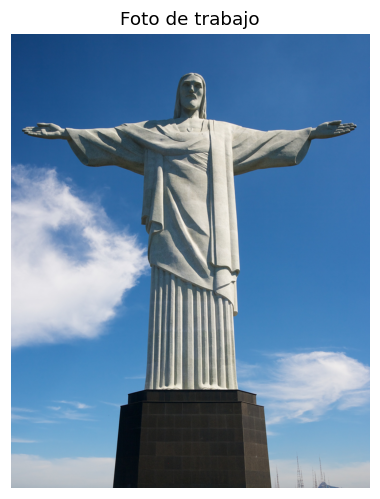

In [2]:
def cargar_imagen(url, local="cristo_redentor_2496x3194.jpg"):
    try:
        r = requests.get(url, timeout=30)
        r.raise_for_status()
        return Image.open(io.BytesIO(r.content)).convert("RGB")
    except Exception as e:
        print("No se pudo descargar desde GitHub (", type(e).__name__, "); se usa el archivo local.")
        return Image.open(local).convert("RGB")

foto = cargar_imagen(URL)
print("Imagen original (ancho x alto):", foto.size)

alto_t = round(foto.height * ANCHO_TRABAJO / foto.width)
rgb = np.asarray(foto.resize((ANCHO_TRABAJO, alto_t), Image.LANCZOS)) / 255.0
alto = ((alto_t - 1) // MULTIPLO) * MULTIPLO + 1
ancho = ((ANCHO_TRABAJO - 1) // MULTIPLO) * MULTIPLO + 1
rgb = rgb[alto_t - alto:, :ancho]          # se recorta por arriba (cielo)
print("Imagen de trabajo (alto x ancho):", rgb.shape[:2])
print()

fig, ax = plt.subplots(figsize=(4.2, 5.4))
ax.imshow(rgb); ax.set_title("Foto de trabajo"); ax.axis("off")
plt.show()

## 2. Segmentación: estatua vs. aire

- Binarizar por brillo NO sirvió en este caso: la piedra de la estatua es casi tan clara como las nubes y la bruma del horizonte.

- Lo que sí distingue bastante al cielo es el **color**: es muy azul. Esto permite simplemente usar el canal $b^*$ de CIELAB (negativo = azul):

1. **Cielo:** $b^*$ (suavizado) $<-14$. Esto también captura los bordes azulados de las nubes y las sombras de la estatua quedan por fuera (son grises, $b^*\approx-5$ a $-10$).
2. **Nubes y bruma:** zonas claras y no azules ($L^*>55$). Se limpian con una apertura morfológica y nos quedamos con los bloques grandes que **tocan el borde** izquierdo, derecho o inferior de la imagen: esos son nubes o bruma. Las partes claras de la estatua nunca tocan esos bordes.
3. **Estatua:** lo que queda (ni cielo ni nube), la componente conexa más grande, con cierre morfológico y relleno de huecos, y una última apertura para quitar rebabas.

Fracción de la imagen clasificada como estatua: 28.4%



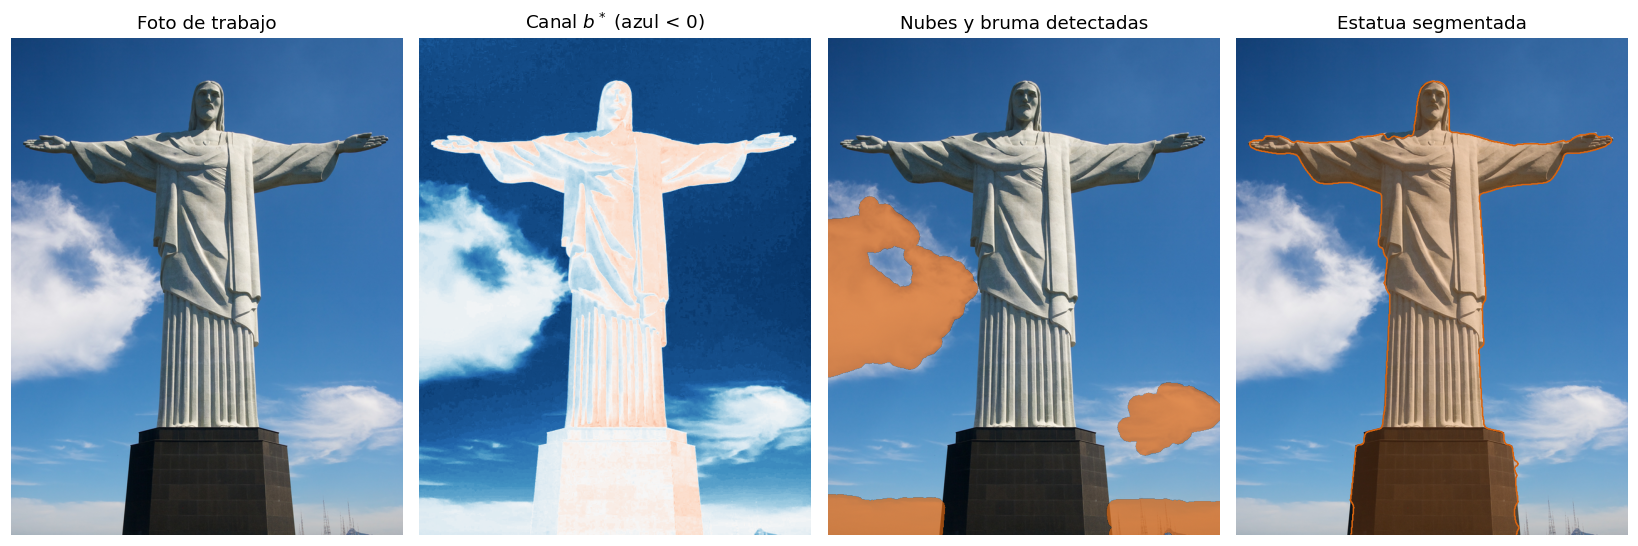

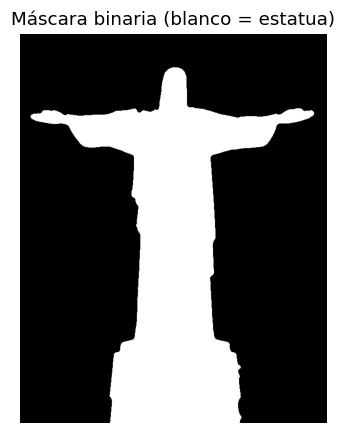

In [3]:
def _morfo(op, mascara, r):
    # operación morfológica con borde replicado (para evitar edge-clipping de los bordes de la imagen)
    p = r + 1
    padded = np.pad(mascara, p, mode="edge")
    return op(padded, structure=morphology.disk(r))[p:-p, p:-p]

abrir   = lambda m, r: _morfo(ndi.binary_opening, m, r)
cerrar  = lambda m, r: _morfo(ndi.binary_closing, m, r)
dilatar = lambda m, r: _morfo(ndi.binary_dilation, m, r)

def componente_mayor(m):
    etiq = measure.label(m, connectivity=1)
    areas = np.bincount(etiq.ravel()); areas[0] = 0
    return etiq == areas.argmax()

def segmentar_estatua(rgb, umbral_b=-14.0, radio_nube=9, margen=6):
    # Devuelve la máscara (True = estatua) y las etapas intermedias, para poder graficarlas.
    lab = color.rgb2lab(rgb)
    L, b = lab[..., 0], lab[..., 2]
    alto, ancho = L.shape

    azul = filters.gaussian(b, 1) < umbral_b # 1) cielo
    claro = (L > 55) & ~azul                 # 2) cosas claras que no son azules
    nucleos = abrir(claro, radio_nube)
    etiquetas = measure.label(nucleos)
    fondo_claro = np.zeros_like(nucleos)
    for reg in measure.regionprops(etiquetas):
        r0, c0, r1, c1 = reg.bbox
        if c0 <= margen or c1 >= ancho - margen or r1 >= alto - margen: # toca el borde -> nube/bruma
            fondo_claro |= (etiquetas == reg.label)
    fondo_claro = dilatar(fondo_claro, 6)

    candidato = abrir(~azul & ~fondo_claro, 2) # 3) lo demás es la estatua
    estatua = componente_mayor(candidato)
    estatua = ndi.binary_fill_holes(cerrar(estatua, 4))
    estatua = componente_mayor(abrir(estatua, 4))
    return estatua, dict(b=b, azul=azul, fondo_claro=fondo_claro)

estatua_px, etapas = segmentar_estatua(rgb)
print(f"Fracción de la imagen clasificada como estatua: {estatua_px.mean():.1%}\n")

fig, ax = plt.subplots(1, 4, figsize=(15, 5.6))
ax[0].imshow(rgb); ax[0].set_title("Foto de trabajo")
im = ax[1].imshow(etapas["b"], cmap="RdBu_r", vmin=-40, vmax=40); ax[1].set_title("Canal $b^*$ (azul < 0)")
ax[2].imshow(rgb)
fc = etapas["fondo_claro"]
ax[2].imshow(np.ma.masked_where(~fc, fc.astype(float)), cmap=ListedColormap([COLOR_ESTATUA_NODO]), alpha=0.7, vmin=0, vmax=1)
ax[2].set_title("Nubes y bruma detectadas")
ax[3].imshow(rgb); ax[3].contour(estatua_px, levels=[0.5], colors=COLOR_ESTATUA_NODO, linewidths=1.0)
ax[3].imshow(np.ma.masked_where(~estatua_px, estatua_px.astype(float)), cmap=ListedColormap([COLOR_ESTATUA_NODO]), alpha=0.25, vmin=0, vmax=1)
ax[3].set_title("Estatua segmentada")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# máscara binaria sola
fig, ax = plt.subplots(figsize=(3.6, 4.6))
ax.imshow(estatua_px, cmap="gray"); ax.set_title("Máscara binaria (blanco = estatua)"); ax.axis("off")
plt.show()

## 3. La malla uniforme

El dominio $\Omega$ es el rectángulo resultante de la imagen. Ponemos los nodos cada `PASO` píxeles en ambas direcciones, así que $h_x=h_y=h$. Normalizamos el ancho a $x\in[0,1]$, por lo que $$h=\text{PASO}/(\text{ancho}-1)\\L_y=(n_y-1)h\approx1.27\;.$$
Además, note que:
- El nodo $(i,j)$ está en la columna $i$ (eje $x$) y en la fila $j$ **contada desde abajo** (eje $y$), con barrido de abajo hacia arriba.
- Un nodo se clasifica como **estatua** si al menos la mitad de los píxeles de su vecindad de `PASO`×`PASO` lo son; si no, es **aire**.

Malla: 313 x 397 nodos  ->  N = 124,261 nodos en total
h = 0.00321   Lx = 1.000   Ly = 1.269
Nodos de estatua: 35,400   Nodos de aire: 88,861



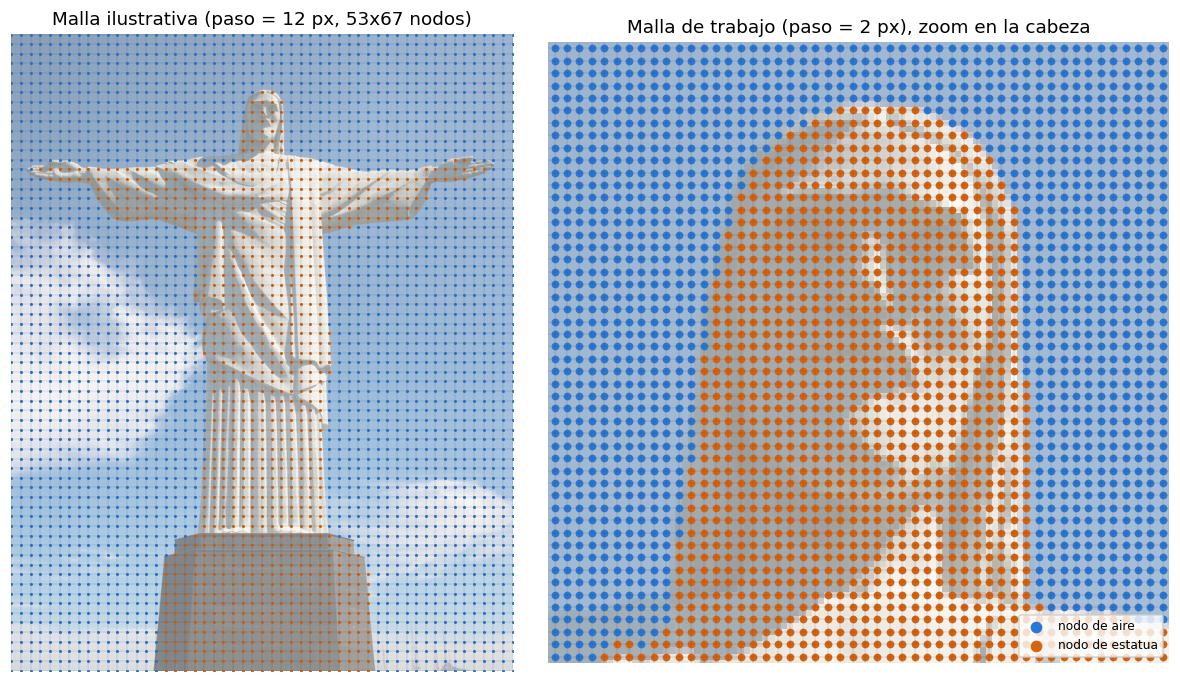

In [4]:
def construir_malla(estatua_px, paso):
    # Malla uniforme con h_x = h_y = h. Los arreglos de nodos se indexan [j, i] con j = 0 abajo.
    alto, ancho = estatua_px.shape
    assert (ancho - 1) % paso == 0 and (alto - 1) % paso == 0, "PASO debe dividir a (ancho-1) y (alto-1)"
    nx, ny = (ancho - 1) // paso + 1, (alto - 1) // paso + 1
    h = paso / (ancho - 1)
    fraccion = ndi.uniform_filter(estatua_px.astype(float), size=paso, mode="nearest")
    cols = np.arange(nx) * paso                     # columna de píxel de cada i
    filas = (alto - 1) - np.arange(ny) * paso       # fila de píxel de cada j (j = 0 es la fila de abajo)
    estatua = fraccion[np.ix_(filas, cols)] >= 0.5
    return SimpleNamespace(paso=paso, h=h, nx=nx, ny=ny, Lx=(nx - 1) * h, Ly=(ny - 1) * h,
                           estatua=estatua, cols=cols, filas=filas,
                           x=np.arange(nx) * h, y=np.arange(ny) * h)

M = construir_malla(estatua_px, PASO)
print(f"Malla: {M.nx} x {M.ny} nodos  ->  N = {M.nx*M.ny:,} nodos en total")
print(f"h = {M.h:.5f}   Lx = {M.Lx:.3f}   Ly = {M.Ly:.3f}")
print(f"Nodos de estatua: {M.estatua.sum():,}   Nodos de aire: {(~M.estatua).sum():,}\n")

def dibujar_malla(ax, rgb, M, ventana=None, tam=8, fondo=0.5):
    alto, ancho = rgb.shape[:2]
    ax.imshow(rgb, alpha=fondo)
    ax.vlines(M.cols, 0, alto - 1, colors=TINTA, linewidths=0.25, alpha=0.35)
    ax.hlines(M.filas, 0, ancho - 1, colors=TINTA, linewidths=0.25, alpha=0.35)
    C, F = np.meshgrid(M.cols, M.filas)
    ax.scatter(C[~M.estatua], F[~M.estatua], s=tam, c=AZUL[3], linewidths=0, label="nodo de aire")
    ax.scatter(C[M.estatua], F[M.estatua], s=tam, c=COLOR_ESTATUA_NODO, linewidths=0, label="nodo de estatua")
    if ventana is not None:
        c0, c1, r0, r1 = ventana
        ax.set_xlim(c0, c1); ax.set_ylim(r1, r0)
    ax.axis("off")

# Zona de zoom: la cabeza
r_top, c_top = np.nonzero(estatua_px)[0].min(), int(np.mean(np.nonzero(estatua_px[np.nonzero(estatua_px)[0].min()])[0]))
ventana_cabeza = (c_top - 50, c_top + 50, r_top - 10, r_top + 90)

M_demo = construir_malla(estatua_px, 12)     # malla gruesa, solo para ilustrar
fig, ax = plt.subplots(1, 2, figsize=(11, 6.2), gridspec_kw=dict(width_ratios=[1, 1.15]))
dibujar_malla(ax[0], rgb, M_demo, tam=4)
ax[0].set_title(f"Malla ilustrativa (paso = 12 px, {M_demo.nx}x{M_demo.ny} nodos)")
dibujar_malla(ax[1], rgb, M, ventana=ventana_cabeza, tam=26, fondo=0.45)
ax[1].set_title(f"Malla de trabajo (paso = {PASO} px), zoom en la cabeza")
ax[1].legend(loc="lower right", frameon=True, fontsize=8, markerscale=1.5)
plt.tight_layout(); plt.show()

## 4. El sistema lineal $A\mathbf v=\mathbf b$

Observe que, básicamente, hay una incógnita por nodo $N=n_x n_y$, indexada con $p=i+j\,n_x$ para recorrer la malla con barrido estilo _raster_ (por filas, de abajo hacia arriba, y de izquierda a derecha). Cada fila de $A$ es de una de dos tipos:

- **Nodo de aire** (incógnita): los cinco coeficientes del esquema, $(-4,\,1,\,1,\,1,\,1)$ en las columnas $p,\,p\mp1,\,p\mp n_x$, con $b_p=0$. En las columnas laterales el vecino que falta se reemplaza por el espejo, lo que duplica el coeficiente del vecino interior.

- **Nodo con valor "impuesto"** (estatua, frontera inferior, frontera superior): una fila de la identidad, $v_p=g_p$, con $g_p=0$ en la estatua y abajo y $g_p=1$ arriba.

$A$ es una matriz altamente dispersa ($\leq 5$ entradas por fila), así que se guarda en formato disperso y se resuelve con un solver directo disperso, por practicidad.

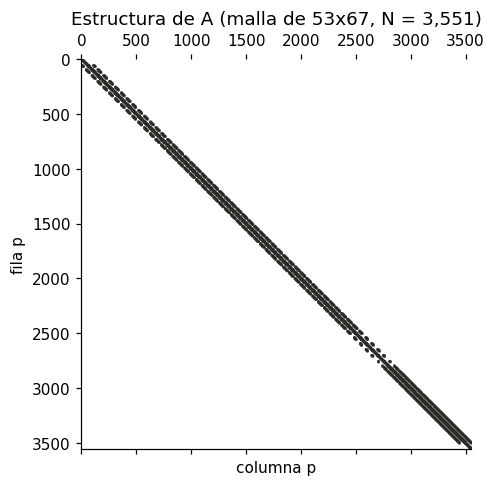


Las diagonales a ±1 y ±n_x son los vecinos (p±1, p±n_x) del esquema de 5 puntos.


In [5]:
def ensamblar(M, con_estatua=True):
    # Armar A v = b para la malla M, con p = i + j*nx. Devuelve A (CSR), b y la máscara de nodos con valor impuesto.
    nx, ny = M.nx, M.ny
    N = nx * ny
    estatua = M.estatua if con_estatua else np.zeros_like(M.estatua)

    # Nodos con valor impuesto (Dirichlet): estatua, frontera inferior y frontera superior
    g = np.zeros((ny, nx))
    dirichlet = estatua.copy()
    dirichlet[0, :] = True       # abajo:  V = 0
    dirichlet[-1, :] = True      # arriba: V = 1
    g[-1, :] = 1.0

    # Nodos de aire (incógnitas): esquema de 5 puntos
    J, I = np.nonzero(~dirichlet)
    P = I + J * nx
    oeste = np.where(I > 0, P - 1, P + 1)        # borde izquierdo: nodo fantasma = espejo (Neumann)
    este = np.where(I < nx - 1, P + 1, P - 1)    # borde derecho:   nodo fantasma = espejo (Neumann)
    D = np.flatnonzero(dirichlet.ravel())

    filas = np.concatenate([P, P, P, P, P, D])
    columnas = np.concatenate([P, oeste, este, P - nx, P + nx, D])
    valores = np.concatenate([np.full(P.size, -4.0), np.ones(4 * P.size), np.ones(D.size)])
    A = sp.coo_matrix((valores, (filas, columnas)), shape=(N, N)).tocsr()   # las entradas repetidas se suman (el "2" de Neumann)

    b = np.zeros(N)
    b[D] = g.ravel()[D]
    return A, b, dirichlet

def resolver(M, con_estatua=True):
    A, b, _ = ensamblar(M, con_estatua)
    V = spla.spsolve(A.tocsc(), b).reshape(M.ny, M.nx)
    return V, A, b

# Estructura de A en la malla ilustrativa
A_demo, _, _ = ensamblar(M_demo)
fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.spy(A_demo, markersize=0.15, color=TINTA)
ax.set_title(f"Estructura de A (malla de {M_demo.nx}x{M_demo.ny}, N = {A_demo.shape[0]:,})")
ax.set_xlabel("columna p"); ax.set_ylabel("fila p")
plt.show()
print("\nLas diagonales a ±1 y ±n_x son los vecinos (p±1, p±n_x) del esquema de 5 puntos.")

In [6]:
# --- Stats ---
t0 = time.perf_counter()
V, A, b = resolver(M)
dt = time.perf_counter() - t0
print(f"--- Stats ---")
print(f"N = {A.shape[0]:,} incógnitas, {A.nnz:,} entradas no nulas, solución en {dt:.2f} s\n")

# --- Verificaciones ---
aire = ~M.estatua
print(f"--- Verificaciones ---")
print(f"Residual  ||A v - b||_inf = {np.linalg.norm(A @ V.ravel() - b, np.inf):.2e}")
print(f"Principio del máximo discreto (i.e., valores extremos en las fronteras): min V = {V[aire].min():.4f}, max V = {V[aire].max():.4f}  (debe estar en [0, 1])\n")

# Sin estatua la solución exacta es lineal, V = y / Ly, y el esquema la reproduce sin error
V_lin, _, _ = resolver(M, con_estatua=False)
print(f"--- ¿Qué pasa si se resuelve el sistema sin estatua? ---")
print(f"Sin estatua: error máximo contra V = y/Ly:  {np.abs(V_lin - (M.y / M.Ly)[:, None]).max():.2e}")

--- Stats ---
N = 124,261 incógnitas, 476,939 entradas no nulas, solución en 1.71 s

--- Verificaciones ---
Residual  ||A v - b||_inf = 3.11e-15
Principio del máximo discreto (i.e., valores extremos en las fronteras): min V = 0.0000, max V = 1.0000  (debe estar en [0, 1])

--- ¿Qué pasa si se resuelve el sistema sin estatua? ---
Sin estatua: error máximo contra V = y/Ly:  2.88e-13


## 5. El potencial o voltaje $V(x,y)$ sobre la silueta de la estatua

- Los nodos de la estatua valen 0 (se pintan en gris, con su contorno).

- En el aire, las líneas finas son **equipotenciales** (i.e., con igual magnitud de voltaje) $V=0.1,0.2,\dots,0.9$.

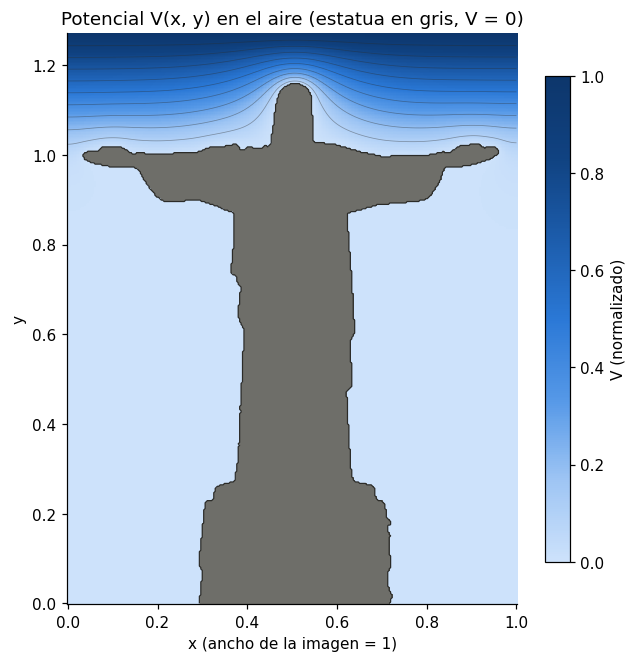

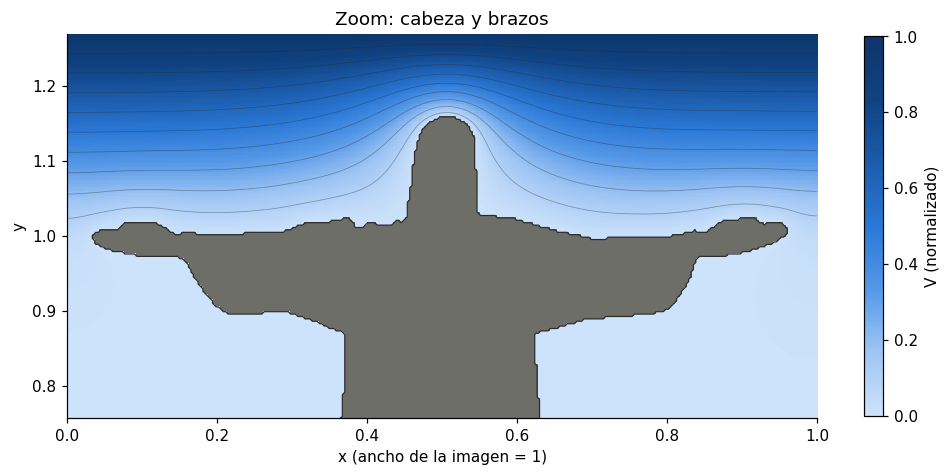

In [7]:
ext = (-M.h / 2, M.Lx + M.h / 2, -M.h / 2, M.Ly + M.h / 2)    # cada nodo es el centro de una celda de lado h

def pintar_silueta(ax):
    ax.imshow(np.where(M.estatua, 1.0, np.nan), origin="lower", extent=ext, cmap=ListedColormap([GRIS_ESTATUA]),
              vmin=0, vmax=1, interpolation="nearest")
    ax.contour(M.x, M.y, M.estatua.astype(float), levels=[0.5], colors=TINTA, linewidths=0.8)

def pintar_potencial(ax, interp="nearest"):
    Vm = np.ma.masked_where(M.estatua, V)
    im = ax.imshow(Vm, origin="lower", extent=ext, cmap=cmap_V, vmin=0, vmax=1, interpolation=interp)
    ax.contour(M.x, M.y, Vm, levels=np.arange(0.1, 1.0, 0.1), colors=TINTA, linewidths=0.5, alpha=0.4)
    pintar_silueta(ax)
    ax.set_xlabel("x (ancho de la imagen = 1)"); ax.set_ylabel("y")
    return im

fig, ax = plt.subplots(figsize=(6.6, 8.2))
im = pintar_potencial(ax)
ax.set_title("Potencial V(x, y) en el aire (estatua en gris, V = 0)")
fig.colorbar(im, ax=ax, shrink=0.7, label="V (normalizado)")
plt.show()

# espacio en blacno
print("\n\n")

# Zoom a la parte alta (cabeza y brazos), donde el potencial cambia más rápido
y_cabeza = M.y[np.nonzero(M.estatua)[0].max()]
fig, ax = plt.subplots(figsize=(11, 5.6))
im = pintar_potencial(ax)
ax.set_xlim(0, M.Lx); ax.set_ylim(y_cabeza - 0.40, M.Ly)
ax.set_title("Zoom: cabeza y brazos")
fig.colorbar(im, ax=ax, shrink=0.8, label="V (normalizado)")
plt.show()

## 6. Campo eléctrico y "mapa de riesgo o probabilidad" (extra por diversión)

[Siendo técnicos](https://www.noaa.gov/jetstream/lightning/how-lightning-is-created), que un rayo aparezca (o se genere) NO lo "decide" el potencial o voltaje en sí, sino el **campo eléctrico** $\mathbf E=-\nabla V$: las descargas parten donde la magnitud del campo $|\mathbf E|$ es más intensa, y eso ocurre en puntas y aristas ([efecto de las puntas](https://incb.com.mx/curso-de-electronica/98-banco-de-informaciones-almanaque/7189-efecto-de-las-puntas-alm184s)).

Entonces, podemos calcular $\mathbf E$ con diferencias centradas y lo comparamos con el campo uniforme que habría sin estatua, $E_0=1/L_y$:

$$\beta=\frac{|\mathbf E|}{E_0}\qquad(\beta=1\ \text{es el campo "sin estatua"}).$$

Sobre la **superficie** de la estatua estimamos el campo normal con el potencial del nodo de aire vecino, $E_n\approx V_{\text{aire}}/h$ (porque $V=0$ en la estatua).

Máximos locales del campo en la superficie de la estatua:


,x,y,beta
pico,,,
1,0.516,1.157,21.071
2,0.952,1.016,8.141
3,0.077,1.016,7.843
4,0.837,1.006,5.953
5,0.317,1.016,5.666
6,0.721,0.997,4.218


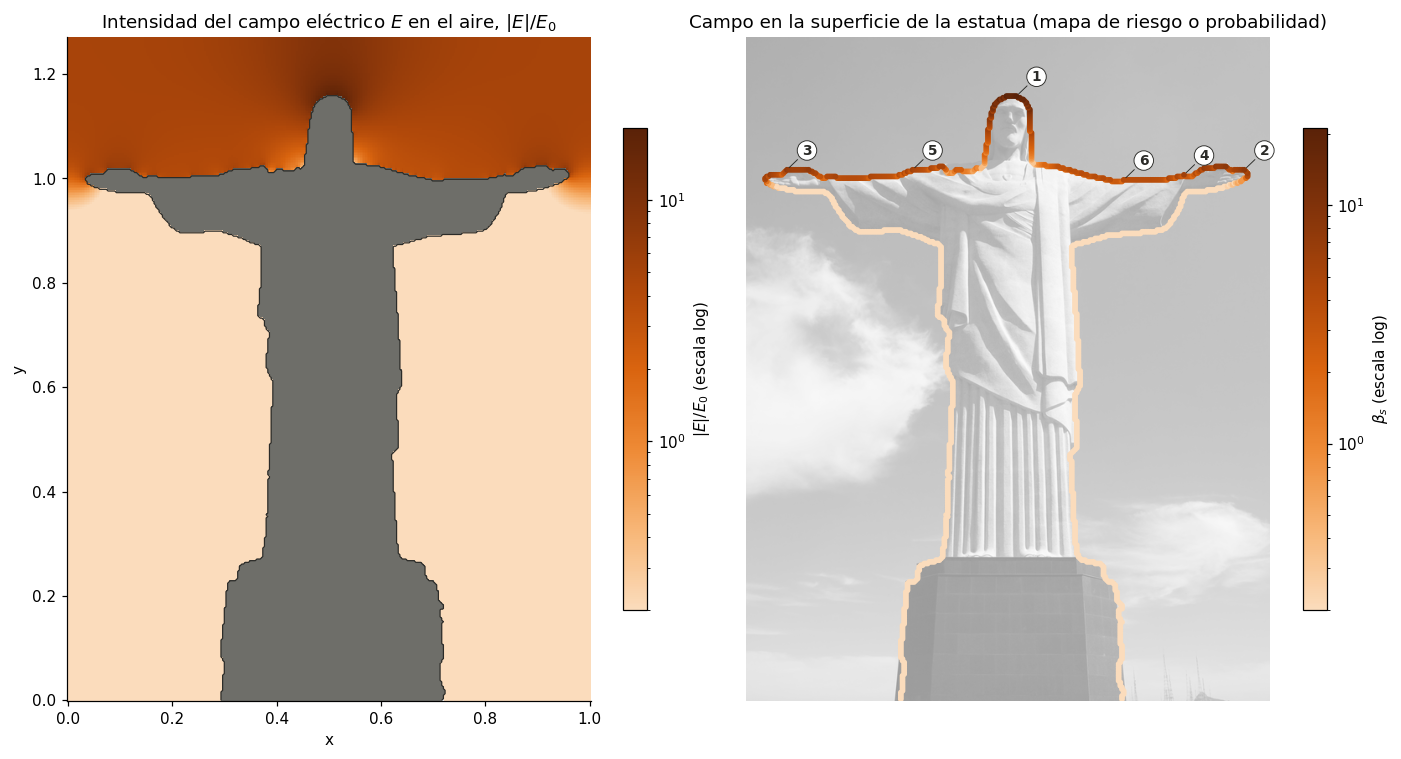

In [8]:
E0 = 1.0 / M.Ly
Ey, Ex = np.gradient(-V, M.h) # np.gradient devuelve (d/dy, d/dx) para arrays [fila=y, columna=x]
beta = np.hypot(Ex, Ey) / E0

def campo_en_superficie(V, M):
    # beta_s en los nodos de estatua que tocan aire: E_n ≈ V_aire / h, normalizado con E0
    est = M.estatua
    Vp, Ap = np.pad(V, 1), np.pad(~est, 1)
    Vn = np.zeros_like(V)
    for dj, di in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
        sl = (slice(1 + dj, 1 + dj + M.ny), slice(1 + di, 1 + di + M.nx))
        Vn = np.maximum(Vn, np.where(Ap[sl], Vp[sl], 0.0))
    borde = est & (Vn > 0)
    return borde, Vn / M.h / E0

def picos(beta_s, borde, M, k=6, separacion=0.10):
    # Los k máximos del campo en la superficie, separados al menos `separacion` entre sí
    J, I = np.nonzero(borde)
    vals = beta_s[J, I]
    elegidos = []
    for o in np.argsort(vals)[::-1]:
        x, y = I[o] * M.h, J[o] * M.h
        if all(np.hypot(x - xs, y - ys) > separacion for _, _, xs, ys, _ in elegidos) or not elegidos:
            elegidos.append((I[o], J[o], x, y, vals[o]))
        if len(elegidos) == k:
            break
    return elegidos

borde, beta_s = campo_en_superficie(V, M)
top = picos(beta_s, borde, M)
tabla = pd.DataFrame([dict(pico=n + 1, x=x, y=y, beta=bs) for n, (i, j, x, y, bs) in enumerate(top)]).set_index("pico")
print("Máximos locales del campo en la superficie de la estatua:")
display(tabla.round(3))
print()

fig, ax = plt.subplots(1, 2, figsize=(13, 7.6), gridspec_kw=dict(width_ratios=[1, 1]))

# (a) |E| / E0 en el aire (escala logarítmica)
beta_aire = np.ma.masked_where(M.estatua, beta)
im = ax[0].imshow(beta_aire, origin="lower", extent=ext, cmap=cmap_E, interpolation="nearest",
                  norm=LogNorm(vmin=0.2, vmax=max(10.0, float(beta_aire.max()))))
pintar_silueta(ax[0])
ax[0].set_title(r"Intensidad del campo eléctrico $E$ en el aire, $|E|/E_0$")
ax[0].set_xlabel("x"); ax[0].set_ylabel("y")
fig.colorbar(im, ax=ax[0], shrink=0.6, label=r"$|E|/E_0$ (escala log)")

# (b) campo en la superficie sobre la foto
alto_px = rgb.shape[0]
ax[1].imshow(color.rgb2gray(rgb), cmap="gray", vmin=0, vmax=1, alpha=0.4)
C, F = np.meshgrid(M.cols, M.filas)
sc = ax[1].scatter(C[borde], F[borde], c=beta_s[borde], s=14, cmap=cmap_E, linewidths=0,
                   norm=LogNorm(vmin=max(0.2, beta_s[borde].min()), vmax=beta_s[borde].max()))
for n, (i, j, x, y, bs) in enumerate(top):
    ax[1].annotate(str(n + 1), (M.cols[i], M.filas[j]), xytext=(10, 10), textcoords="offset points",
                   fontsize=9, fontweight="bold", color=TINTA,
                   bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec=TINTA, lw=0.6),
                   arrowprops=dict(arrowstyle="-", color=TINTA, lw=0.6))
ax[1].set_title("Campo en la superficie de la estatua (mapa de riesgo o probabilidad)")
ax[1].axis("off")
fig.colorbar(sc, ax=ax[1], shrink=0.6, label=r"$\beta_s$ (escala log)")
plt.tight_layout(); plt.show()

## 7. ¿Dónde es más probable que caigan los rayos? (extra por diversión)

### **¿Qué muestra el potencial?**
La estatua está a $V=0$ y se comporta como una pantalla:
- Por debajo de los brazos el aire queda casi a $V\approx0$ (la túnica y el pedestal quedan "protegidos").
- Mientras que las equipotenciales se aprietan justo encima de la cabeza y de los brazos, donde el potencial sube de ≈0 a 1 en una distancia corta. Equipotenciales juntas significan $|\nabla V|$ grande, i.e., campo intenso.

**¿Dónde es más probable que caiga el rayo?**

Según el campo en la superficie $\beta_s$ (sección 6):

<div align="center">

| Zona | Picos | $\beta_s$ |
|---|---|---|
| Parte superior de la cabeza | 1 | ≈ 21 |
| Manos y dedos (extremos de los brazos) | 2 y 3 | ≈ 8 |
| Borde superior de los brazos | 4, 5 y 6 | ≈ 4 – 6 |
| Todo el cuerpo bajo los brazos (túnica, pedestal) | — | < 0.03 |

</div>

Esto básicamente soporta la intuición anterior:
- Los rayos buscan lo más alto y lo más puntiagudo. Lo primero que "ve" la nube es la cabeza, luego las manos y el borde superior de los brazos; ahí el campo es entre 4 y 21 veces el que habría sin estatua.
- En cambio, la túnica y el pedestal quedan protegidos (¿apantallados?) por los hombros y los brazos (campo cientos de veces menor que el uniforme), así que es muy poco probable que el rayo llegue hasta ellos.

### **Contraste con la realidad**
Este resultado es consistente con lo documentado: la estatua fue alcanzada por rayos en 2008 (dedos, cabeza y cejas) y en 2014 (un dedo de la mano derecha), según [Wikipedia](https://en.wikipedia.org/wiki/Christ_the_Redeemer_%28statue%29). Son justo las zonas que el modelo marca como de campo más alto. O, de manera gráfica:

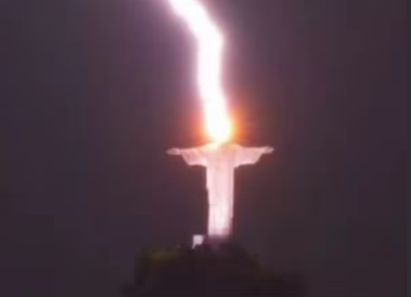

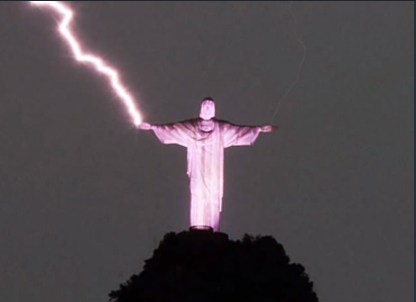

## 8. ¿Qué cambia si se refina la malla? (extra por diversión)

Se repite el cálculo con pasos 8, 6, 4, 3 y 2 px. Se compara:
1. El potencial o voltaje en un punto de aire fijo, justo encima de la cabeza.
2. El máximo del campo en la superficie, $\beta_{\max}$.

In [9]:
x_prueba = M.x[int(np.round(c_top / M.paso))]
y_prueba = y_cabeza + 0.05 # 0.05 por encima de la cabeza
print(f"Punto de prueba: (x, y) = ({x_prueba:.3f}, {y_prueba:.3f})")

filas_tabla = []
for paso in (8, 6, 4, 3, 2):
    Mk = construir_malla(estatua_px, paso)
    t0 = time.perf_counter(); Vk, Ak, _ = resolver(Mk); tk = time.perf_counter() - t0
    Vprueba = ndi.map_coordinates(Vk, [[y_prueba / Mk.h], [x_prueba / Mk.h]], order=1)[0]
    bk, bsk = campo_en_superficie(Vk, Mk)
    filas_tabla.append(dict(paso_px=paso, h=Mk.h, malla=f"{Mk.nx}x{Mk.ny}", N=Ak.shape[0], V_prueba=Vprueba,
                            beta_max=bsk[bk].max(), tiempo_s=tk))
refin = pd.DataFrame(filas_tabla).set_index("paso_px")
display(refin.round({"h": 5, "V_prueba": 5, "beta_max": 2, "tiempo_s": 2}))

p = np.polyfit(np.log(refin["h"]), np.log(refin["beta_max"]), 1)[0]
print(f"Ajuste log-log: beta_max ~ h^{p:.2f}")

Punto de prueba: (x, y) = (0.500, 1.207)


,h,malla,N,V_prueba,beta_max,tiempo_s
paso_px,,,,,,
8,0.01282,79x100,7900,0.55114,17.52,0.05
6,0.00962,105x133,13965,0.54101,17.75,0.13
4,0.00641,157x199,31243,0.54080,18.61,0.24
3,0.00481,209x265,55385,0.53731,20.37,0.48
2,0.00321,313x397,124261,0.53010,21.07,1.22


Ajuste log-log: beta_max ~ h^-0.15


### **Resultados (con los parámetros por defecto)**
1. El potencial o voltaje en el punto de prueba cambia poco al refinar la malla (de 0.551 con paso 8 a 0.530 con paso 2, unos 4 %), pero no de forma monótona: parte de esa variación no es error del esquema, sino que la silueta en escalera (y los detalles finos que alcanza a captar) cambia con el paso.

2. El máximo del campo $\beta_{\max}$ sí crece al refinar malla (de 17.5 a 21.1; ajuste ≈ $h^{-0.15}$): cerca de una punta o esquina convexa el campo teórico es singular, así que su valor numérico depende de la malla. **Nota:** por esta razón es que en la sección 6 conviene leer *dónde* está el campo alto (posiciones relativas), no el valor absoluto de $\beta$.

### **Limitaciones del modelo**
- **Es un modelo 2D**: una silueta frontal tratada como si fuera un cilindro infinito en la dirección perpendicular a la imagen.

- **La frontera de la estatua queda en "escalera" o _staircase_** (i.e., los nodos de la malla aproximan fronteras curveadas de manera rígida), [lo cual resulta en un error geométrico](https://www.csc.kth.se/~olofr/Publications/staircase.pdf) de orden $h$ cerca de la superficie.

- **El potencial/campo estático es solo una primera aproximación:** la física real del rayo depende además de otras cosas como la dinámica de las cargas y del aire ionizado, i.e., [existen modelos más avanzados del fenómeno](https://unige.iris.cineca.it/bitstream/11567/1140356/1/energies-16-02436-v2.pdf).